In [1]:
%pip install mysql-connector-python sqlalchemy

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\ASUS\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [2]:
import pandas as pd
import numpy as np
import mysql.connector

from sqlalchemy import create_engine

In [ ]:
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="password",
    database="creditcardfrauddb",
    port=3306
)

if conn.is_connected():
    print("MySQL Connected Successfully!")

MySQL Connected Successfully!


In [4]:
cursor = conn.cursor()

cursor.execute("SELECT DATABASE()")

result = cursor.fetchone()

print("Connected Database:", result[0])

Connected Database: creditcardfrauddb


In [8]:
cursor.execute("SHOW TABLES")

for table in cursor.fetchall():
    print(table)

('credit_card_transactions',)


In [9]:
df = pd.read_csv("C:\\Users\\ASUS\\Desktop\\DA project\\dataset\\credit_card_fraud_cleaned.csv")

print("Dataset Loaded Successfully!")

print("Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Shape: (500000, 18)


,transaction_id,customer_id,transaction_datetime,transaction_date,transaction_hour,merchant,merchant_category,transaction_amount,payment_method,transaction_status,city,state,customer_latitude,customer_longitude,merchant_latitude,merchant_longitude,city_population,is_fraud
0,164a9d7cc011f54155e746d270d03524,CUST_0E606C366809,2019-08-04 06:51:47,2019-08-04,6,Torp-Labadie,gas_transport,64.07,Swipe,Approved,Alpharetta,GA,34.0770,-84.3033,34.697441,-85.167109,165556,0
1,62466599f86f6c65ad665f7dedea7fe4,CUST_C51B7DBC7448,2020-03-08 11:46:55,2020-03-08,11,"Greenholt, Jacobi and Gleason",gas_transport,70.77,Swipe,Approved,Lawrence,MA,42.6911,-71.1605,42.105635,-71.744017,76383,0
2,4699d5d458cc9e7b0317cad10db9ad25,CUST_6684A1525185,2020-01-12 15:57:29,2020-01-12,15,Harris Group,food_dining,21.84,Chip,Approved,Amorita,OK,36.9412,-98.2458,36.760724,-97.475362,83,0
3,0ec8223375e03bc6aa1b2c8cdb8df5cf,CUST_987E3D10EE11,2020-06-19 19:40:32,2020-06-19,19,Schuppe-Schuppe,food_dining,55.25,Swipe,Approved,Carlotta,CA,40.5070,-123.9743,40.785266,-123.638540,1139,0
4,b3011f4000f41dd273dea2283584f755,CUST_FAB1B59015E0,2019-09-12 16:02:50,2019-09-12,16,"Boehm, Block and Jakubowski",misc_pos,41.10,Online,Approved,Newberg,OR,45.3099,-122.9685,44.755678,-122.072899,28278,0


In [10]:
print("Total Records:", len(df))

print("Total Columns:", len(df.columns))

print("\nColumn Names:")
print(df.columns.tolist())

Total Records: 500000
Total Columns: 18

Column Names:
['transaction_id', 'customer_id', 'transaction_datetime', 'transaction_date', 'transaction_hour', 'merchant', 'merchant_category', 'transaction_amount', 'payment_method', 'transaction_status', 'city', 'state', 'customer_latitude', 'customer_longitude', 'merchant_latitude', 'merchant_longitude', 'city_population', 'is_fraud']


In [11]:
cursor.execute("DESCRIBE credit_card_transactions")

mysql_columns = [column[0] for column in cursor.fetchall()]

print("MySQL Columns:")
print(mysql_columns)

print("\nCSV Columns:")
print(df.columns.tolist())

MySQL Columns:
['transaction_id', 'customer_id', 'transaction_datetime', 'transaction_date', 'transaction_hour', 'merchant', 'merchant_category', 'transaction_amount', 'payment_method', 'transaction_status', 'city', 'state', 'customer_latitude', 'customer_longitude', 'merchant_latitude', 'merchant_longitude', 'city_population', 'is_fraud']

CSV Columns:
['transaction_id', 'customer_id', 'transaction_datetime', 'transaction_date', 'transaction_hour', 'merchant', 'merchant_category', 'transaction_amount', 'payment_method', 'transaction_status', 'city', 'state', 'customer_latitude', 'customer_longitude', 'merchant_latitude', 'merchant_longitude', 'city_population', 'is_fraud']


In [12]:
if df.columns.tolist() == mysql_columns:
    print("Column Names and Order Matched Successfully!")
else:
    print("Column Mapping Mismatch!")

Column Names and Order Matched Successfully!


In [13]:
df['transaction_datetime'] = pd.to_datetime(
    df['transaction_datetime'],
    errors='coerce'
)

df['transaction_date'] = pd.to_datetime(
    df['transaction_date'],
    errors='coerce'
).dt.date

In [14]:
print(df[['transaction_datetime', 'transaction_date']].dtypes)

transaction_datetime    datetime64[ns]
transaction_date                object
dtype: object


In [15]:
print(
    "Duplicate Transaction IDs:",
    df['transaction_id'].duplicated().sum()
)

Duplicate Transaction IDs: 0


In [16]:
print("Missing Transaction IDs:", df['transaction_id'].isna().sum())

Missing Transaction IDs: 0


In [ ]:
from sqlalchemy import create_engine, URL

engine_url = URL.create(
    drivername="mysql+mysqlconnector",
    username="root",
    password="password",
    host="localhost",
    port=3306,
    database="creditcardfrauddb"
)

engine = create_engine(engine_url)

print("SQLAlchemy Engine Created Successfully!")

SQLAlchemy Engine Created Successfully!


In [6]:
with engine.connect() as connection:

    result = connection.exec_driver_sql(
        "SELECT DATABASE()"
    )

    print("Connected Database:", result.scalar())

Connected Database: creditcardfrauddb


In [7]:
with engine.connect() as connection:

    result = connection.exec_driver_sql(
        "SELECT COUNT(*) FROM credit_card_transactions"
    )

    existing_records = result.scalar()

print("Existing Records:", existing_records)

Existing Records: 500000


In [8]:
if existing_records == 0:

    df.to_sql(
        name='credit_card_transactions',
        con=engine,
        if_exists='append',
        index=False,
        chunksize=2000
    )

    print("Data Imported Successfully!")

else:
    print("Import Cancelled: Table already contains records.")

Import Cancelled: Table already contains records.


In [9]:
with engine.connect() as connection:

    result = connection.exec_driver_sql(
        "SELECT COUNT(*) FROM credit_card_transactions"
    )

    total_records = result.scalar()

print("Total Records:", total_records)

Total Records: 500000


In [22]:
query = """
SELECT
    is_fraud,
    COUNT(*) AS total_transactions
FROM credit_card_transactions
GROUP BY is_fraud;
"""

fraud_data = pd.read_sql(query, engine)

fraud_data

,is_fraud,total_transactions
0,0,497106
1,1,2894


In [23]:
query = """
SELECT
    SUM(transaction_amount) AS total_transaction_amount
FROM credit_card_transactions;
"""

total_amount = pd.read_sql(query, engine)

total_amount

,total_transaction_amount
0,35395944.09


In [24]:
query = """
SELECT
    SUM(transaction_amount) AS fraudulent_amount
FROM credit_card_transactions
WHERE is_fraud = 1;
"""

fraud_amount = pd.read_sql(query, engine)

fraud_amount

,fraudulent_amount
0,1581912.11


In [25]:
query = """
SELECT
    MIN(transaction_amount) AS minimum_amount,
    MAX(transaction_amount) AS maximum_amount,
    AVG(transaction_amount) AS average_amount
FROM credit_card_transactions;
"""

amount_summary = pd.read_sql(query, engine)

amount_summary

,minimum_amount,maximum_amount,average_amount
0,1.0,28948.9,70.791888


In [26]:
python_count = len(df)

mysql_count = pd.read_sql(
    "SELECT COUNT(*) AS total FROM credit_card_transactions",
    engine
)['total'][0]

print("Python Records:", python_count)
print("MySQL Records:", mysql_count)

if python_count == mysql_count:
    print("Data Verification Successful!")
else:
    print("Record Count Mismatch!")

Python Records: 500000
MySQL Records: 500000
Data Verification Successful!


In [27]:
# SQL Question 1: Count Total Transactions
query = """
SELECT
    COUNT(*) AS total_transactions
FROM credit_card_transactions;
"""

result = pd.read_sql(query, engine)

result

,total_transactions
0,500000


In [28]:
# SQL Question 2: Calculate Total Transaction Amount
query = """
SELECT
    SUM(transaction_amount) AS total_transaction_amount
FROM credit_card_transactions;
"""

result = pd.read_sql(query, engine)

result

,total_transaction_amount
0,35395944.09


In [29]:
# Question 4: Calculate Fraud Percentage
query = """
SELECT
    COUNT(*) AS total_transactions,
    SUM(is_fraud) AS fraudulent_transactions,
    ROUND(
        (SUM(is_fraud) / COUNT(*)) * 100,
        2
    ) AS fraud_percentage
FROM credit_card_transactions;
"""

fraud_percentage = pd.read_sql(query, engine)

fraud_percentage

,total_transactions,fraudulent_transactions,fraud_percentage
0,500000,2894.0,0.58


In [30]:
# Question 5: Find Customers with the Highest Transaction Value
query = """
SELECT
    customer_id,
    COUNT(*) AS total_transactions,
    ROUND(SUM(transaction_amount), 2) AS total_spending
FROM credit_card_transactions
GROUP BY customer_id
ORDER BY total_spending DESC
LIMIT 10;
"""

top_customers = pd.read_sql(query, engine)

top_customers

,customer_id,total_transactions,total_spending
0,CUST_3F128965B93D,1186,121905.68
1,CUST_A3A62304E057,1196,114755.28
2,CUST_FA46922D7B8A,1204,113715.86
3,CUST_8715D9E40DC2,1162,112027.96
4,CUST_CD81464D3E96,1154,111833.19
5,CUST_5B9E1E38487F,1193,111076.21
6,CUST_82BC011F90F9,1175,110738.66
7,CUST_E2097D89A4B2,1238,110403.78
8,CUST_B82BF3D7EBC1,1182,110297.57
9,CUST_B4FA0AABA467,1251,108153.52


In [31]:
# Question 6: Analyze Transactions by Merchant Category
query = """
SELECT
    merchant_category,
    COUNT(*) AS total_transactions,
    ROUND(SUM(transaction_amount), 2) AS total_transaction_amount,
    ROUND(AVG(transaction_amount), 2) AS average_transaction_amount,
    SUM(is_fraud) AS fraudulent_transactions,
    ROUND(SUM(is_fraud) * 100.0 / COUNT(*), 2) AS fraud_percentage
FROM credit_card_transactions
GROUP BY merchant_category
ORDER BY total_transaction_amount DESC;
"""

merchant_analysis = pd.read_sql(query, engine)

merchant_analysis

,merchant_category,total_transactions,total_transaction_amount,average_transaction_amount,fraudulent_transactions,fraud_percentage
0,grocery_pos,47682,5575257.81,116.93,641.0,1.34
1,shopping_pos,45050,3594166.47,79.78,326.0,0.72
2,shopping_net,37539,3407909.83,90.78,693.0,1.85
3,gas_transport,50785,3223400.84,63.47,247.0,0.49
4,home,47281,2772278.76,58.63,90.0,0.19
5,kids_pets,43642,2520498.55,57.75,85.0,0.19
6,entertainment,36454,2354194.17,64.58,89.0,0.24
7,misc_net,24447,1996390.57,81.66,372.0,1.52
8,misc_pos,30678,1898913.79,61.90,89.0,0.29
9,travel,15624,1848202.58,118.29,43.0,0.28


In [32]:
# SQL Question 7: Analyze Hourly Transaction Trends
query = """
SELECT
    transaction_hour,
    COUNT(*) AS total_transactions,
    SUM(is_fraud) AS fraudulent_transactions,
    ROUND(SUM(is_fraud) * 100.0 / COUNT(*), 2) AS fraud_percentage
FROM credit_card_transactions
GROUP BY transaction_hour
ORDER BY transaction_hour;
"""

hourly_analysis = pd.read_sql(query, engine)

hourly_analysis

,transaction_hour,total_transactions,fraudulent_transactions,fraud_percentage
0,0,16379,237.0,1.45
1,1,16560,248.0,1.50
2,2,16407,241.0,1.47
3,3,16627,235.0,1.41
4,4,16143,19.0,0.12
5,5,16316,25.0,0.15
6,6,16361,17.0,0.10
7,7,16376,21.0,0.13
8,8,16454,10.0,0.06
9,9,16142,15.0,0.09


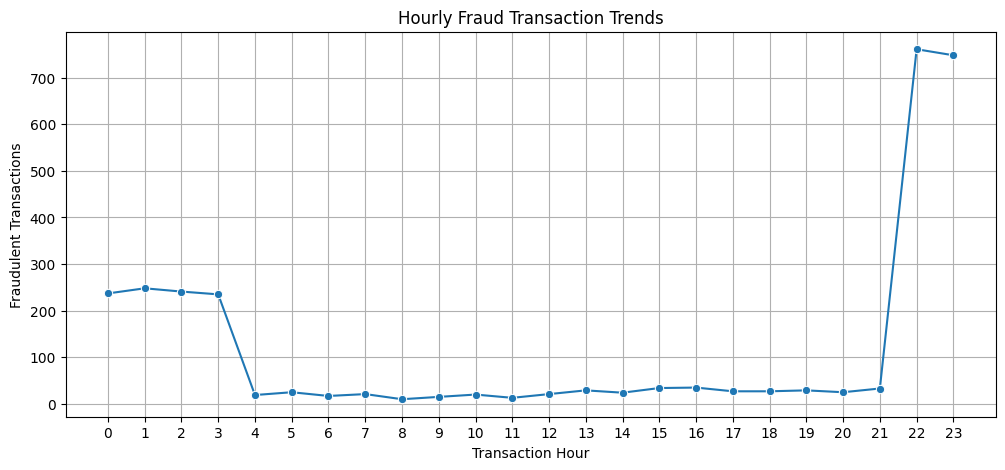

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_analysis,
    x='transaction_hour',
    y='fraudulent_transactions',
    marker='o'
)

plt.title("Hourly Fraud Transaction Trends")
plt.xlabel("Transaction Hour")
plt.ylabel("Fraudulent Transactions")
plt.xticks(range(24))
plt.grid(True)

plt.show()

In [34]:
# SQL Question 8: Rank Customers by Transaction Amount
query = """
SELECT
    customer_id,
    total_spending,
    RANK() OVER (
        ORDER BY total_spending DESC
    ) AS customer_rank
FROM
(
    SELECT
        customer_id,
        SUM(transaction_amount) AS total_spending
    FROM credit_card_transactions
    GROUP BY customer_id
) AS customer_summary
ORDER BY customer_rank
LIMIT 20;
"""

customer_ranking = pd.read_sql(query, engine)

customer_ranking

,customer_id,total_spending,customer_rank
0,CUST_3F128965B93D,121905.68,1
1,CUST_A3A62304E057,114755.28,2
2,CUST_FA46922D7B8A,113715.86,3
3,CUST_8715D9E40DC2,112027.96,4
4,CUST_CD81464D3E96,111833.19,5
5,CUST_5B9E1E38487F,111076.21,6
6,CUST_82BC011F90F9,110738.66,7
7,CUST_E2097D89A4B2,110403.78,8
8,CUST_B82BF3D7EBC1,110297.57,9
9,CUST_B4FA0AABA467,108153.52,10


In [35]:
# SQL Question 9: Calculate Average Transaction Amount
query = """
SELECT
    ROUND(AVG(transaction_amount), 2)
    AS average_transaction_amount
FROM credit_card_transactions;
"""

average_transaction = pd.read_sql(query, engine)

average_transaction

,average_transaction_amount
0,70.79


In [36]:
# SQL Question 10: Identify Suspicious Transaction Locations
query = """
SELECT
    city,
    state,
    COUNT(*) AS total_transactions,
    SUM(is_fraud) AS fraudulent_transactions,
    ROUND(
        SUM(is_fraud) * 100.0 / COUNT(*),
        2
    ) AS fraud_percentage
FROM credit_card_transactions
GROUP BY city, state
HAVING SUM(is_fraud) > 0
ORDER BY fraudulent_transactions DESC
LIMIT 20;
"""

location_analysis = pd.read_sql(query, engine)

location_analysis

,city,state,total_transactions,fraudulent_transactions,fraud_percentage
0,Houston,TX,1648,18.0,1.09
1,Tulsa,OK,1177,14.0,1.19
2,San Antonio,TX,1972,13.0,0.66
3,Detroit,MI,1404,11.0,0.78
4,Naples,FL,1602,11.0,0.69
5,Albuquerque,NM,367,10.0,2.72
6,Freedom,WY,784,10.0,1.28
7,Lowell,OR,627,10.0,1.59
8,Bay City,OR,219,9.0,4.11
9,Bonfield,IL,600,9.0,1.50


In [37]:
# Question 11: Fraud Analysis Using CTE
query = """
WITH merchant_fraud AS
(
    SELECT
        merchant_category,
        COUNT(*) AS total_transactions,
        SUM(is_fraud) AS fraudulent_transactions,
        SUM(transaction_amount) AS total_amount,
        ROUND(
            SUM(is_fraud) * 100.0 / COUNT(*),
            2
        ) AS fraud_percentage
    FROM credit_card_transactions
    GROUP BY merchant_category
)

SELECT *
FROM merchant_fraud
WHERE total_transactions >= 1000
ORDER BY fraud_percentage DESC;
"""

cte_result = pd.read_sql(query, engine)

cte_result

,merchant_category,total_transactions,fraudulent_transactions,total_amount,fraud_percentage
0,shopping_net,37539,693.0,3407909.83,1.85
1,misc_net,24447,372.0,1996390.57,1.52
2,grocery_pos,47682,641.0,5575257.81,1.34
3,shopping_pos,45050,326.0,3594166.47,0.72
4,gas_transport,50785,247.0,3223400.84,0.49
5,misc_pos,30678,89.0,1898913.79,0.29
6,travel,15624,43.0,1848202.58,0.28
7,personal_care,34941,84.0,1675878.67,0.24
8,entertainment,36454,89.0,2354194.17,0.24
9,grocery_net,17647,42.0,943037.94,0.24


In [38]:
# Question 12: Identify High-Risk Customers
query = """
SELECT
    customer_id,
    COUNT(*) AS total_transactions,
    SUM(is_fraud) AS fraudulent_transactions,
    ROUND(SUM(transaction_amount), 2) AS total_spending,

    CASE
        WHEN SUM(is_fraud) >= 3 THEN 'High Risk'
        WHEN SUM(is_fraud) BETWEEN 1 AND 2 THEN 'Medium Risk'
        ELSE 'Low Risk'
    END AS customer_risk

FROM credit_card_transactions

GROUP BY customer_id

ORDER BY fraudulent_transactions DESC;
"""

customer_risk = pd.read_sql(query, engine)

customer_risk

,customer_id,total_transactions,fraudulent_transactions,total_spending,customer_risk
0,CUST_0340538D8B29,627,10.0,40504.04,High Risk
1,CUST_4687CEAD8DED,784,10.0,50941.20,High Risk
2,CUST_14A503C2C0A0,219,9.0,15421.88,High Risk
3,CUST_5379911D4E34,600,9.0,38098.63,High Risk
4,CUST_5B32948AEC52,1020,9.0,61537.44,High Risk
...,...,...,...,...,...
977,CUST_FAB1B59015E0,392,0.0,24430.71,Low Risk
978,CUST_FC171FB97D51,585,0.0,41909.67,Low Risk
979,CUST_FC77EB46FB0D,788,0.0,44363.19,Low Risk
980,CUST_FDEC06CEC99B,210,0.0,20319.83,Low Risk


In [39]:
# Question 13: Customer Ranking Using Window Functions
query = """
SELECT
    customer_id,
    total_spending,
    RANK() OVER (
        ORDER BY total_spending DESC
    ) AS customer_rank
FROM
(
    SELECT
        customer_id,
        SUM(transaction_amount) AS total_spending
    FROM credit_card_transactions
    GROUP BY customer_id
) AS customer_summary
ORDER BY customer_rank
LIMIT 20;
"""

customer_ranking = pd.read_sql(query, engine)

customer_ranking

,customer_id,total_spending,customer_rank
0,CUST_3F128965B93D,121905.68,1
1,CUST_A3A62304E057,114755.28,2
2,CUST_FA46922D7B8A,113715.86,3
3,CUST_8715D9E40DC2,112027.96,4
4,CUST_CD81464D3E96,111833.19,5
5,CUST_5B9E1E38487F,111076.21,6
6,CUST_82BC011F90F9,110738.66,7
7,CUST_E2097D89A4B2,110403.78,8
8,CUST_B82BF3D7EBC1,110297.57,9
9,CUST_B4FA0AABA467,108153.52,10


In [40]:
query = "SELECT VERSION() AS mysql_version"

version = pd.read_sql(query, engine)

version

,mysql_version
0,8.0.44


In [45]:
# Next: Q13.3 – Rank Customers Within Risk Categories
query = """
WITH customer_risk AS (
    SELECT
        customer_id,
        COUNT(*) AS total_transactions,
        SUM(is_fraud) AS fraud_count,
        SUM(transaction_amount) AS total_spending,

        CASE
            WHEN SUM(is_fraud) >= 3 THEN 'High Risk'
            WHEN SUM(is_fraud) >= 1 THEN 'Medium Risk'
            ELSE 'Low Risk'
        END AS risk_category

    FROM credit_card_transactions
    GROUP BY customer_id
),

customer_ranking AS (
    SELECT
        customer_id,
        risk_category,
        total_transactions,
        fraud_count,
        total_spending,

        RANK() OVER (
            PARTITION BY risk_category
            ORDER BY total_spending DESC
        ) AS spending_rank

    FROM customer_risk
)

SELECT *
FROM customer_ranking
ORDER BY risk_category, spending_rank;
"""

risk_customer_ranking = pd.read_sql_query(query, engine)

risk_customer_ranking

,customer_id,risk_category,total_transactions,fraud_count,total_spending,spending_rank
0,CUST_FA46922D7B8A,High Risk,1204,7.0,113715.86,1
1,CUST_E2097D89A4B2,High Risk,1238,3.0,110403.78,2
2,CUST_B4FA0AABA467,High Risk,1251,8.0,108153.52,3
3,CUST_84892A2ED0E0,High Risk,1201,5.0,105817.69,4
4,CUST_37EA83EBD668,High Risk,1168,3.0,104496.40,5
...,...,...,...,...,...,...
977,CUST_C2DBAB0A8EE3,Medium Risk,2,2.0,922.82,190
978,CUST_2DD3F6E01B83,Medium Risk,1,1.0,830.24,191
979,CUST_A2DF23B3AC27,Medium Risk,2,2.0,296.44,192
980,CUST_8874C0E84541,Medium Risk,2,2.0,286.98,193


In [46]:
query = """
WITH customer_risk AS (
    SELECT
        customer_id,
        SUM(is_fraud) AS fraud_count,
        SUM(transaction_amount) AS total_spending,

        CASE
            WHEN SUM(is_fraud) >= 3 THEN 'High Risk'
            WHEN SUM(is_fraud) >= 1 THEN 'Medium Risk'
            ELSE 'Low Risk'
        END AS risk_category

    FROM credit_card_transactions
    GROUP BY customer_id
),

ranked_customers AS (
    SELECT
        customer_id,
        risk_category,
        fraud_count,
        total_spending,

        ROW_NUMBER() OVER (
            PARTITION BY risk_category
            ORDER BY total_spending DESC
        ) AS spending_rank

    FROM customer_risk
)

SELECT *
FROM ranked_customers
WHERE spending_rank <= 5
ORDER BY risk_category, spending_rank;
"""

top_customers = pd.read_sql_query(query, engine)

top_customers

,customer_id,risk_category,fraud_count,total_spending,spending_rank
0,CUST_FA46922D7B8A,High Risk,7.0,113715.86,1
1,CUST_E2097D89A4B2,High Risk,3.0,110403.78,2
2,CUST_B4FA0AABA467,High Risk,8.0,108153.52,3
3,CUST_84892A2ED0E0,High Risk,5.0,105817.69,4
4,CUST_37EA83EBD668,High Risk,3.0,104496.40,5
5,CUST_3F128965B93D,Low Risk,0.0,121905.68,1
6,CUST_82BC011F90F9,Low Risk,0.0,110738.66,2
7,CUST_B82BF3D7EBC1,Low Risk,0.0,110297.57,3
8,CUST_1791D00B0F61,Low Risk,0.0,101002.30,4
9,CUST_5D1B3FD0878E,Low Risk,0.0,98716.65,5


In [47]:
# Q14.1 – Find Transactions Above the Average Transaction Amount
query = """
SELECT
    transaction_id,
    customer_id,
    transaction_amount,
    merchant,
    merchant_category,
    transaction_datetime,
    is_fraud
FROM credit_card_transactions
WHERE transaction_amount > (
    SELECT AVG(transaction_amount)
    FROM credit_card_transactions
)
ORDER BY transaction_amount DESC;
"""

above_average_transactions = pd.read_sql_query(query, engine)

above_average_transactions.head(20)

,transaction_id,customer_id,transaction_amount,merchant,merchant_category,transaction_datetime,is_fraud
0,309c4bf7fc47b1ddee5ad883bcf634b6,CUST_D1EC40C9A134,28948.90,Satterfield-Lowe,travel,2019-12-01 16:19:23,0
1,916093eeab1831be71d49362bf5b7be5,CUST_6684A1525185,27119.77,"Monahan, Hermann and Johns",travel,2020-05-30 17:31:30,0
2,dda9d800d37a9fc2c086a836d66b0588,CUST_E798B2A50D4F,26544.12,Boyer-Haley,travel,2019-09-14 22:19:01,0
3,0b902a1e549c98b949444a7557da2403,CUST_C51B7DBC7448,25086.94,Hackett Group,travel,2019-06-14 20:15:38,0
4,17242c80d9a67bac27901c0676ab56aa,CUST_EA387B4D2B4E,15305.95,"Reichel, Bradtke and Blanda",travel,2020-04-02 14:23:21,0
5,a3eee563b00b16af433ceb069178da74,CUST_AA99BCFA289D,14849.74,Lynch-Mohr,travel,2020-06-02 18:45:24,0
6,c3fd5aeb603b150ce5c05c7ee38ada97,CUST_FBB6735C0B1D,14630.68,Ankunding-Carroll,travel,2019-03-28 16:53:47,0
7,529cdd779b6da5a8cdbaa1be199de35c,CUST_30586AF63CC1,14467.64,"Kunze, Larkin and Mayert",travel,2019-07-27 23:29:50,0
8,15a465ee61ec3590e1fbfa47e090b7c1,CUST_1A43EECB1582,14238.11,"Hodkiewicz, Prohaska and Paucek",travel,2020-05-12 13:05:00,0
9,f9cfe12e60a45b9dc6f33336ddaf954f,CUST_BC4DF8CE7DFA,14112.59,Reichert-Weissnat,travel,2019-08-19 21:34:27,0


In [10]:
query = """
SELECT
    customer_id,
    SUM(transaction_amount) AS total_spending,
    COUNT(transaction_id) AS total_transactions

FROM credit_card_transactions
GROUP BY customer_id

HAVING SUM(transaction_amount) > (
    SELECT AVG(customer_total)
    FROM (
        SELECT
            SUM(transaction_amount) AS customer_total
        FROM credit_card_transactions
        GROUP BY customer_id
    ) AS customer_spending
)

ORDER BY total_spending DESC;
"""

above_average_customers = pd.read_sql_query(query, engine)

above_average_customers

,customer_id,total_spending,total_transactions
0,CUST_3F128965B93D,121905.68,1186
1,CUST_A3A62304E057,114755.28,1196
2,CUST_FA46922D7B8A,113715.86,1204
3,CUST_8715D9E40DC2,112027.96,1162
4,CUST_CD81464D3E96,111833.19,1154
...,...,...,...
454,CUST_1C153C3ED422,36280.08,598
455,CUST_90A3FD8086F9,36240.08,610
456,CUST_64F668544FE1,36232.54,397
457,CUST_C5729962BA8D,36108.54,607


In [11]:
query = """
SELECT
    customer_id,
    COUNT(*) AS total_transactions,
    SUM(is_fraud) AS fraud_transactions,
    SUM(transaction_amount) AS total_spending

FROM credit_card_transactions

GROUP BY customer_id

HAVING SUM(is_fraud) > 0

ORDER BY fraud_transactions DESC, total_spending DESC;
"""

fraud_customers = pd.read_sql_query(query, engine)

fraud_customers

,customer_id,total_transactions,fraud_transactions,total_spending
0,CUST_4687CEAD8DED,784,10.0,50941.20
1,CUST_0340538D8B29,627,10.0,40504.04
2,CUST_6ECAE9DE0A50,946,9.0,73810.74
3,CUST_5B32948AEC52,1020,9.0,61537.44
4,CUST_9A34AEC9DABE,992,9.0,60413.65
...,...,...,...,...
747,CUST_DEADF612328B,170,1.0,8586.43
748,CUST_A7A9CC3D59E4,177,1.0,8489.94
749,CUST_AE7EE5CA769E,1,1.0,1313.18
750,CUST_2DD3F6E01B83,1,1.0,830.24


In [12]:
# Q15.1 – Customer Fraud and Spending Analysis
query = """
WITH customer_summary AS (
    SELECT
        customer_id,
        COUNT(*) AS total_transactions,
        SUM(transaction_amount) AS total_spending
    FROM credit_card_transactions
    GROUP BY customer_id
),

fraud_summary AS (
    SELECT
        customer_id,
        SUM(is_fraud) AS fraud_transactions
    FROM credit_card_transactions
    GROUP BY customer_id
)

SELECT
    c.customer_id,
    c.total_transactions,
    c.total_spending,
    COALESCE(f.fraud_transactions, 0) AS fraud_transactions

FROM customer_summary c

LEFT JOIN fraud_summary f
    ON c.customer_id = f.customer_id

ORDER BY fraud_transactions DESC, total_spending DESC;
"""

customer_fraud_analysis = pd.read_sql_query(query, engine)

customer_fraud_analysis

,customer_id,total_transactions,total_spending,fraud_transactions
0,CUST_4687CEAD8DED,784,50941.20,10.0
1,CUST_0340538D8B29,627,40504.04,10.0
2,CUST_6ECAE9DE0A50,946,73810.74,9.0
3,CUST_5B32948AEC52,1020,61537.44,9.0
4,CUST_9A34AEC9DABE,992,60413.65,9.0
...,...,...,...,...
977,CUST_00686B4DD655,196,9371.40,0.0
978,CUST_75573BF25062,197,9195.96,0.0
979,CUST_73F8337B63D6,198,9002.46,0.0
980,CUST_1F5E323177DF,192,8106.69,0.0


In [13]:
# Q15.2 – Identify High-Value Fraud Customers
query = """
WITH customer_summary AS (
    SELECT
        customer_id,
        COUNT(*) AS total_transactions,
        SUM(transaction_amount) AS total_spending,
        SUM(is_fraud) AS fraud_transactions
    FROM credit_card_transactions
    GROUP BY customer_id
),

high_risk_customers AS (
    SELECT
        customer_id,
        total_transactions,
        total_spending,
        fraud_transactions
    FROM customer_summary
    WHERE fraud_transactions >= 3
      AND total_spending > 50000
)

SELECT
    *,
    RANK() OVER (
        ORDER BY total_spending DESC
    ) AS spending_rank
FROM high_risk_customers
ORDER BY total_spending DESC;
"""

high_value_fraud_customers = pd.read_sql_query(query, engine)

high_value_fraud_customers


,customer_id,total_transactions,total_spending,fraud_transactions,spending_rank
0,CUST_FA46922D7B8A,1204,113715.86,7.0,1
1,CUST_E2097D89A4B2,1238,110403.78,3.0,2
2,CUST_B4FA0AABA467,1251,108153.52,8.0,3
3,CUST_84892A2ED0E0,1201,105817.69,5.0,4
4,CUST_37EA83EBD668,1168,104496.40,3.0,5
...,...,...,...,...,...
121,CUST_01F37B9A3B6B,792,50602.28,4.0,122
122,CUST_0F6D41AD3D34,599,50384.25,4.0,123
123,CUST_F996C540E96E,579,50304.79,3.0,124
124,CUST_234D3464C6F5,794,50122.04,3.0,125


In [14]:
# Q15.2 – Identify High-Value Fraud Customers
query = """
WITH customer_summary AS (
    SELECT
        customer_id,
        COUNT(*) AS total_transactions,
        SUM(transaction_amount) AS total_spending,
        SUM(is_fraud) AS fraud_transactions
    FROM credit_card_transactions
    GROUP BY customer_id
),

high_risk_customers AS (
    SELECT *
    FROM customer_summary
    WHERE fraud_transactions >= 3
      AND total_spending > 50000
)

SELECT
    *,
    RANK() OVER (
        ORDER BY total_spending DESC
    ) AS spending_rank
FROM high_risk_customers
ORDER BY total_spending DESC;
"""

high_value_fraud_customers = pd.read_sql_query(query, engine)

high_value_fraud_customers

,customer_id,total_transactions,total_spending,fraud_transactions,spending_rank
0,CUST_FA46922D7B8A,1204,113715.86,7.0,1
1,CUST_E2097D89A4B2,1238,110403.78,3.0,2
2,CUST_B4FA0AABA467,1251,108153.52,8.0,3
3,CUST_84892A2ED0E0,1201,105817.69,5.0,4
4,CUST_37EA83EBD668,1168,104496.40,3.0,5
...,...,...,...,...,...
121,CUST_01F37B9A3B6B,792,50602.28,4.0,122
122,CUST_0F6D41AD3D34,599,50384.25,4.0,123
123,CUST_F996C540E96E,579,50304.79,3.0,124
124,CUST_234D3464C6F5,794,50122.04,3.0,125


In [15]:
# Q15.3 – Merchant Category Fraud Analysis
query = """
WITH category_summary AS (
    SELECT
        merchant_category,
        COUNT(*) AS total_transactions,
        SUM(transaction_amount) AS total_revenue,
        SUM(is_fraud) AS fraud_transactions
    FROM credit_card_transactions
    GROUP BY merchant_category
),

category_analysis AS (
    SELECT
        merchant_category,
        total_transactions,
        total_revenue,
        fraud_transactions,
        ROUND(
            fraud_transactions * 100.0 / total_transactions,
            2
        ) AS fraud_percentage
    FROM category_summary
)

SELECT *
FROM category_analysis
ORDER BY fraud_percentage DESC;
"""

merchant_fraud_analysis = pd.read_sql_query(query, engine)

merchant_fraud_analysis

,merchant_category,total_transactions,total_revenue,fraud_transactions,fraud_percentage
0,shopping_net,37539,3407909.83,693.0,1.85
1,misc_net,24447,1996390.57,372.0,1.52
2,grocery_pos,47682,5575257.81,641.0,1.34
3,shopping_pos,45050,3594166.47,326.0,0.72
4,gas_transport,50785,3223400.84,247.0,0.49
5,misc_pos,30678,1898913.79,89.0,0.29
6,travel,15624,1848202.58,43.0,0.28
7,personal_care,34941,1675878.67,84.0,0.24
8,entertainment,36454,2354194.17,89.0,0.24
9,grocery_net,17647,943037.94,42.0,0.24


In [16]:
# Q15.4 – Customer Risk Classification and Spending Ranking
query = """
WITH customer_summary AS (
    SELECT
        customer_id,
        COUNT(*) AS total_transactions,
        SUM(transaction_amount) AS total_spending,
        SUM(is_fraud) AS fraud_transactions
    FROM credit_card_transactions
    GROUP BY customer_id
),

customer_risk AS (
    SELECT
        customer_id,
        total_transactions,
        total_spending,
        fraud_transactions,

        CASE
            WHEN fraud_transactions >= 3 THEN 'High Risk'
            WHEN fraud_transactions >= 1 THEN 'Medium Risk'
            ELSE 'Low Risk'
        END AS risk_category

    FROM customer_summary
),

ranked_customers AS (
    SELECT
        *,
        RANK() OVER (
            PARTITION BY risk_category
            ORDER BY total_spending DESC
        ) AS spending_rank
    FROM customer_risk
)

SELECT *
FROM ranked_customers
ORDER BY risk_category, spending_rank;
"""

customer_risk_ranking = pd.read_sql_query(query, engine)

customer_risk_ranking

,customer_id,total_transactions,total_spending,fraud_transactions,risk_category,spending_rank
0,CUST_FA46922D7B8A,1204,113715.86,7.0,High Risk,1
1,CUST_E2097D89A4B2,1238,110403.78,3.0,High Risk,2
2,CUST_B4FA0AABA467,1251,108153.52,8.0,High Risk,3
3,CUST_84892A2ED0E0,1201,105817.69,5.0,High Risk,4
4,CUST_37EA83EBD668,1168,104496.40,3.0,High Risk,5
...,...,...,...,...,...,...
977,CUST_C2DBAB0A8EE3,2,922.82,2.0,Medium Risk,190
978,CUST_2DD3F6E01B83,1,830.24,1.0,Medium Risk,191
979,CUST_A2DF23B3AC27,2,296.44,2.0,Medium Risk,192
980,CUST_8874C0E84541,2,286.98,2.0,Medium Risk,193


In [17]:
# Q16.1 – Extract Year, Month and Day
query = """
SELECT
    transaction_id,
    transaction_datetime,
    YEAR(transaction_datetime) AS transaction_year,
    MONTH(transaction_datetime) AS transaction_month,
    DAY(transaction_datetime) AS transaction_day
FROM credit_card_transactions
LIMIT 20;
"""

date_analysis = pd.read_sql_query(query, engine)

date_analysis

,transaction_id,transaction_datetime,transaction_year,transaction_month,transaction_day
0,00000ecad06b03d3a8d34b4e30b5ce3b,2019-12-15 20:23:10,2019,12,15
1,00001ded488fddab97677128e5034d39,2019-12-23 19:06:40,2019,12,23
2,0000425d184356a21be4b39933c2c0ea,2019-05-20 13:35:26,2019,5,20
3,000048ecb6c1d9337bcc27109b46794d,2019-04-24 02:08:30,2019,4,24
4,000051c6b92f7cd491c41b025d60a933,2019-12-18 22:32:14,2019,12,18
5,0000b45f78355eab64e143fd8cf1d721,2020-04-07 19:35:02,2020,4,7
6,0000ddb86257223f2e75b951bb6b1c13,2019-02-24 10:12:55,2019,2,24
7,000121bf3adda35bc12ffd4db959060e,2019-12-07 00:58:53,2019,12,7
8,000127d6a7195801ee88746dc1b0c0c2,2019-08-26 13:30:36,2019,8,26
9,000169feeab4b72e7a95cc3203edcbfb,2020-05-05 03:41:59,2020,5,5


In [18]:
# Q16.2 – Monthly Transaction Volume and Revenue
query = """
SELECT
    YEAR(transaction_datetime) AS transaction_year,
    MONTH(transaction_datetime) AS transaction_month,
    COUNT(*) AS total_transactions,
    ROUND(SUM(transaction_amount), 2) AS total_revenue,
    SUM(is_fraud) AS fraud_transactions
FROM credit_card_transactions
GROUP BY
    YEAR(transaction_datetime),
    MONTH(transaction_datetime)
ORDER BY transaction_year, transaction_month;
"""

monthly_analysis = pd.read_sql_query(query, engine)

monthly_analysis

,transaction_year,transaction_month,total_transactions,total_revenue,fraud_transactions
0,2019,1,20254,1470186.07,199.0
1,2019,2,19276,1397639.94,211.0
2,2019,3,27503,1982986.35,193.0
3,2019,4,26369,1803586.34,122.0
4,2019,5,27966,1945892.96,147.0
5,2019,6,33334,2353371.96,149.0
6,2019,7,33256,2343577.63,125.0
7,2019,8,33680,2384118.48,150.0
8,2019,9,27118,1916571.65,150.0
9,2019,10,26679,1908234.46,176.0


In [19]:
query = """
SELECT
    transaction_id,
    customer_id,
    transaction_datetime,
    DAYNAME(transaction_datetime) AS day_name,
    transaction_amount,
    merchant_category,
    is_fraud
FROM credit_card_transactions
WHERE DAYOFWEEK(transaction_datetime) IN (1, 7)
ORDER BY transaction_datetime;
"""

weekend_transactions = pd.read_sql_query(query, engine)

weekend_transactions.head(20)

,transaction_id,customer_id,transaction_datetime,day_name,transaction_amount,merchant_category,is_fraud
0,0727732924394c91394845bc5fd5ec21,CUST_F8F184219BEF,2019-01-05 00:00:56,Saturday,47.93,gas_transport,0
1,ff33f5d5301d7cead2fd0e5c96c821d6,CUST_16060FE34696,2019-01-05 00:02:15,Saturday,92.65,gas_transport,0
2,feb99d768ca275d9caf755d090f6d585,CUST_BC6375EAADB5,2019-01-05 00:10:17,Saturday,45.72,shopping_pos,0
3,6895636fac683d1bc04de00655711138,CUST_5447DD5F41E1,2019-01-05 00:17:59,Saturday,5.65,misc_pos,0
4,ecae13a9943eed19e7cd9709a56038ab,CUST_B10466E01E4A,2019-01-05 00:20:38,Saturday,143.39,shopping_pos,0
5,d9ab016ba5b22460d6e172fd8e088655,CUST_B72B3338DA0C,2019-01-05 00:21:15,Saturday,31.83,shopping_pos,0
6,e78cd40f8a124a5c02b7d539b11b7902,CUST_4A6079B33963,2019-01-05 00:21:16,Saturday,134.29,grocery_pos,0
7,b4e003dd26676113ae3269af7ac80779,CUST_642123E396E8,2019-01-05 00:21:56,Saturday,61.95,gas_transport,0
8,0c735956a47733ab759505bd08950c82,CUST_F9D884D74B97,2019-01-05 00:23:42,Saturday,6.50,misc_pos,0
9,ad10140e4bf3ce23a790f83dc018e679,CUST_CB74CC6484CA,2019-01-05 00:34:31,Saturday,83.83,grocery_pos,0


In [20]:
query = """
SELECT
    DATE(transaction_datetime) AS transaction_date,
    COUNT(*) AS total_transactions,
    SUM(is_fraud) AS fraud_transactions,

    ROUND(
        SUM(is_fraud) * 100.0 / COUNT(*),
        2
    ) AS fraud_percentage,

    ROUND(SUM(transaction_amount), 2) AS total_revenue

FROM credit_card_transactions

GROUP BY DATE(transaction_datetime)

ORDER BY transaction_date;
"""

daily_fraud_analysis = pd.read_sql_query(query, engine)

daily_fraud_analysis

,transaction_date,total_transactions,fraud_transactions,fraud_percentage,total_revenue
0,2019-01-01,913,0.0,0.00,55773.81
1,2019-01-02,433,2.0,0.46,25094.08
2,2019-01-03,469,6.0,1.28,33781.17
3,2019-01-04,564,10.0,1.77,41240.04
4,2019-01-05,534,4.0,0.75,35993.71
...,...,...,...,...,...
532,2020-06-17,673,15.0,2.23,57870.67
533,2020-06-18,791,15.0,1.90,74087.86
534,2020-06-19,934,10.0,1.07,72129.77
535,2020-06-20,943,12.0,1.27,64534.25


In [21]:
query = """
SELECT
    CASE
        WHEN DAYOFWEEK(transaction_datetime) IN (1, 7)
        THEN 'Weekend'
        ELSE 'Weekday'
    END AS day_type,

    COUNT(*) AS total_transactions,
    SUM(is_fraud) AS fraud_transactions,

    ROUND(
        SUM(is_fraud) * 100.0 / COUNT(*),
        2
    ) AS fraud_percentage,

    ROUND(AVG(transaction_amount), 2) AS average_transaction_amount

FROM credit_card_transactions

GROUP BY day_type;
"""

weekday_weekend_analysis = pd.read_sql_query(query, engine)

weekday_weekend_analysis

,day_type,total_transactions,fraud_transactions,fraud_percentage,average_transaction_amount
0,Weekend,174220,950.0,0.55,70.08
1,Weekday,325780,1944.0,0.60,71.17


In [22]:
# Q17.1 – Count Fraud and Non-Fraud Transactions
query = """
SELECT
    COUNT(*) AS total_transactions,

    SUM(CASE
        WHEN is_fraud = 1 THEN 1
        ELSE 0
    END) AS fraud_transactions,

    SUM(CASE
        WHEN is_fraud = 0 THEN 1
        ELSE 0
    END) AS non_fraud_transactions

FROM credit_card_transactions;
"""

fraud_count_analysis = pd.read_sql_query(query, engine)

fraud_count_analysis

,total_transactions,fraud_transactions,non_fraud_transactions
0,500000,2894.0,497106.0


In [23]:
# Q17.2 – Compare Fraud and Non-Fraud Transaction Amounts
query = """
SELECT
    ROUND(SUM(CASE
        WHEN is_fraud = 1 THEN transaction_amount
        ELSE 0
    END), 2) AS fraud_amount,

    ROUND(SUM(CASE
        WHEN is_fraud = 0 THEN transaction_amount
        ELSE 0
    END), 2) AS non_fraud_amount,

    ROUND(AVG(CASE
        WHEN is_fraud = 1 THEN transaction_amount
    END), 2) AS avg_fraud_amount,

    ROUND(AVG(CASE
        WHEN is_fraud = 0 THEN transaction_amount
    END), 2) AS avg_non_fraud_amount

FROM credit_card_transactions;
"""

fraud_amount_analysis = pd.read_sql_query(query, engine)

fraud_amount_analysis

,fraud_amount,non_fraud_amount,avg_fraud_amount,avg_non_fraud_amount
0,1581912.11,33814031.98,546.62,68.02


In [24]:
query = """
SELECT
    merchant_category,

    COUNT(*) AS total_transactions,

    SUM(CASE
        WHEN is_fraud = 1 THEN 1
        ELSE 0
    END) AS fraud_transactions,

    SUM(CASE
        WHEN is_fraud = 0 THEN 1
        ELSE 0
    END) AS non_fraud_transactions,

    ROUND(
        SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END)
        * 100.0 / COUNT(*), 2
    ) AS fraud_percentage

FROM credit_card_transactions

GROUP BY merchant_category

ORDER BY fraud_percentage DESC;
"""

category_conditional_analysis = pd.read_sql_query(query, engine)

category_conditional_analysis

,merchant_category,total_transactions,fraud_transactions,non_fraud_transactions,fraud_percentage
0,shopping_net,37539,693.0,36846.0,1.85
1,misc_net,24447,372.0,24075.0,1.52
2,grocery_pos,47682,641.0,47041.0,1.34
3,shopping_pos,45050,326.0,44724.0,0.72
4,gas_transport,50785,247.0,50538.0,0.49
5,misc_pos,30678,89.0,30589.0,0.29
6,travel,15624,43.0,15581.0,0.28
7,personal_care,34941,84.0,34857.0,0.24
8,entertainment,36454,89.0,36365.0,0.24
9,grocery_net,17647,42.0,17605.0,0.24


In [25]:
query = """
SELECT
    merchant_category,

    COUNT(*) AS total_transactions,

    SUM(CASE
        WHEN is_fraud = 1 THEN 1
        ELSE 0
    END) AS fraud_transactions,

    SUM(CASE
        WHEN is_fraud = 0 THEN 1
        ELSE 0
    END) AS non_fraud_transactions,

    ROUND(
        SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END)
        * 100.0 / COUNT(*), 2
    ) AS fraud_percentage

FROM credit_card_transactions

GROUP BY merchant_category

ORDER BY fraud_percentage DESC;
"""

category_conditional_analysis = pd.read_sql_query(query, engine)

category_conditional_analysis

,merchant_category,total_transactions,fraud_transactions,non_fraud_transactions,fraud_percentage
0,shopping_net,37539,693.0,36846.0,1.85
1,misc_net,24447,372.0,24075.0,1.52
2,grocery_pos,47682,641.0,47041.0,1.34
3,shopping_pos,45050,326.0,44724.0,0.72
4,gas_transport,50785,247.0,50538.0,0.49
5,misc_pos,30678,89.0,30589.0,0.29
6,travel,15624,43.0,15581.0,0.28
7,personal_care,34941,84.0,34857.0,0.24
8,entertainment,36454,89.0,36365.0,0.24
9,grocery_net,17647,42.0,17605.0,0.24


In [26]:
query = """
SELECT
    state,

    COUNT(*) AS total_transactions,

    SUM(CASE
        WHEN is_fraud = 1 THEN 1
        ELSE 0
    END) AS fraud_transactions,

    SUM(CASE
        WHEN is_fraud = 0 THEN 1
        ELSE 0
    END) AS non_fraud_transactions,

    ROUND(
        SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END)
        * 100.0 / COUNT(*), 2
    ) AS fraud_percentage

FROM credit_card_transactions

GROUP BY state

ORDER BY fraud_percentage DESC;
"""

state_conditional_analysis = pd.read_sql_query(query, engine)

state_conditional_analysis

,state,total_transactions,fraud_transactions,non_fraud_transactions,fraud_percentage
0,DE,2,2.0,0.0,100.00
1,RI,213,8.0,205.0,3.76
2,AK,819,19.0,800.0,2.32
3,OR,7263,64.0,7199.0,0.88
4,CO,5326,42.0,5284.0,0.79
5,NH,3143,24.0,3119.0,0.76
6,NE,9443,70.0,9373.0,0.74
7,OH,17978,130.0,17848.0,0.72
8,ME,6426,46.0,6380.0,0.72
9,MN,12225,87.0,12138.0,0.71


In [27]:
query = """
SELECT
    payment_method,

    COUNT(*) AS total_transactions,

    SUM(CASE
        WHEN is_fraud = 1 THEN 1
        ELSE 0
    END) AS fraud_transactions,

    SUM(CASE
        WHEN is_fraud = 0 THEN 1
        ELSE 0
    END) AS non_fraud_transactions,

    ROUND(
        SUM(CASE WHEN is_fraud = 1 THEN 1 ELSE 0 END)
        * 100.0 / COUNT(*), 2
    ) AS fraud_percentage,

    ROUND(AVG(transaction_amount), 2) AS average_amount

FROM credit_card_transactions

GROUP BY payment_method

ORDER BY fraud_percentage DESC;
"""

payment_fraud_analysis = pd.read_sql_query(query, engine)

payment_fraud_analysis

,payment_method,total_transactions,fraud_transactions,non_fraud_transactions,fraud_percentage,average_amount
0,Contactless,74520,450.0,74070.0,0.60,70.55
1,Chip,170196,998.0,169198.0,0.59,70.84
2,Swipe,130322,742.0,129580.0,0.57,71.54
3,Online,124962,704.0,124258.0,0.56,70.09


In [28]:
# Q18.1 – Create a Fraud Transactions View
query = """
CREATE OR REPLACE VIEW fraud_transactions_view AS
SELECT
    transaction_id,
    customer_id,
    transaction_datetime,
    merchant,
    merchant_category,
    transaction_amount,
    payment_method,
    city,
    state,
    is_fraud
FROM credit_card_transactions
WHERE is_fraud = 1;
"""

with engine.begin() as connection:
    connection.exec_driver_sql(query)

print("Fraud transactions view created successfully!")

Fraud transactions view created successfully!


In [29]:
query = """
SELECT *
FROM fraud_transactions_view
LIMIT 10;
"""

fraud_view = pd.read_sql_query(query, engine)

fraud_view

,transaction_id,customer_id,transaction_datetime,merchant,merchant_category,transaction_amount,payment_method,city,state,is_fraud
0,002a4565b89c75cef77a70da9bee212f,CUST_6803200992CA,2019-11-14 22:00:28,Lemke-Gutmann,shopping_net,799.88,Online,Washington,DC,1
1,003a2a4550e91554f4c560f87e1424fa,CUST_764DBCD4FC8F,2019-12-22 22:26:53,Reynolds-Schinner,misc_pos,49.47,Contactless,Kirby,OH,1
2,003f607aa5842f3f760c1c2626bb1dab,CUST_BC599295AA7F,2019-05-19 13:24:12,"Stanton, Jakubowski and Baumbach",shopping_net,1007.47,Online,Red Cliff,CO,1
3,00422000408aea213f6432061686b0bd,CUST_52A4D02B32A4,2019-01-22 02:12:36,Friesen Inc,shopping_pos,746.76,Swipe,Sebring,FL,1
4,00504c7cdd153f08bd1f0ba7432a3972,CUST_4D31BF452F90,2019-03-14 23:54:18,Kunze Inc,grocery_pos,315.44,Swipe,Mesa,AZ,1
5,005e292fa43a0113b369e9d2d82aaf54,CUST_022AAE8A2974,2019-11-24 00:47:17,Flatley-Durgan,misc_net,671.93,Chip,Newport,ME,1
6,006c3f03abfc2f1df27d9c73614c97de,CUST_AD21716107FE,2019-03-25 23:05:27,Mohr Inc,shopping_pos,866.89,Chip,Iselin,NJ,1
7,006f9e787453fd5578306116225e238c,CUST_98BE089F7ED9,2019-10-05 22:24:58,Strosin-Cruickshank,grocery_pos,328.72,Online,Yellowstone National Park,WY,1
8,00a0d00a0b7abd0c2fd6b1836dd27dfd,CUST_E5606DFEF3FD,2019-12-03 00:57:34,Kerluke Inc,misc_net,783.46,Chip,Mounds,OK,1
9,00b4018dcaae0bc93b6554646c0973b3,CUST_84CABE5BB4AD,2020-02-02 01:43:32,Kutch and Sons,grocery_pos,282.42,Chip,Hinesburg,VT,1


In [30]:
# Q18.2 – Create Customer Spending View
query = """
CREATE OR REPLACE VIEW customer_spending_view AS
SELECT
    customer_id,
    COUNT(*) AS total_transactions,
    ROUND(SUM(transaction_amount), 2) AS total_spending,
    ROUND(AVG(transaction_amount), 2) AS average_transaction_amount,
    SUM(is_fraud) AS fraud_transactions
FROM credit_card_transactions
GROUP BY customer_id;
"""

with engine.begin() as connection:
    connection.exec_driver_sql(query)

print("Customer spending view created successfully!")

Customer spending view created successfully!


In [31]:
query = """
SELECT *
FROM customer_spending_view
ORDER BY total_spending DESC
LIMIT 20;
"""

customer_view = pd.read_sql_query(query, engine)

customer_view

,customer_id,total_transactions,total_spending,average_transaction_amount,fraud_transactions
0,CUST_3F128965B93D,1186,121905.68,102.79,0.0
1,CUST_A3A62304E057,1196,114755.28,95.95,1.0
2,CUST_FA46922D7B8A,1204,113715.86,94.45,7.0
3,CUST_8715D9E40DC2,1162,112027.96,96.41,1.0
4,CUST_CD81464D3E96,1154,111833.19,96.91,2.0
5,CUST_5B9E1E38487F,1193,111076.21,93.11,1.0
6,CUST_82BC011F90F9,1175,110738.66,94.25,0.0
7,CUST_E2097D89A4B2,1238,110403.78,89.18,3.0
8,CUST_B82BF3D7EBC1,1182,110297.57,93.31,0.0
9,CUST_B4FA0AABA467,1251,108153.52,86.45,8.0


In [32]:
# Q18.3 – Create Merchant Category Fraud View
query = """
CREATE OR REPLACE VIEW merchant_fraud_view AS
SELECT
    merchant_category,
    COUNT(*) AS total_transactions,
    ROUND(SUM(transaction_amount), 2) AS total_revenue,
    SUM(is_fraud) AS fraud_transactions,

    ROUND(
        SUM(is_fraud) * 100.0 / COUNT(*), 2
    ) AS fraud_percentage

FROM credit_card_transactions
GROUP BY merchant_category;
"""

with engine.begin() as connection:
    connection.exec_driver_sql(query)

print("Merchant fraud view created successfully!")

Merchant fraud view created successfully!


In [33]:
query = """
SELECT *
FROM merchant_fraud_view
ORDER BY fraud_percentage DESC;
"""

merchant_view = pd.read_sql_query(query, engine)

merchant_view

,merchant_category,total_transactions,total_revenue,fraud_transactions,fraud_percentage
0,shopping_net,37539,3407909.83,693.0,1.85
1,misc_net,24447,1996390.57,372.0,1.52
2,grocery_pos,47682,5575257.81,641.0,1.34
3,shopping_pos,45050,3594166.47,326.0,0.72
4,gas_transport,50785,3223400.84,247.0,0.49
5,misc_pos,30678,1898913.79,89.0,0.29
6,travel,15624,1848202.58,43.0,0.28
7,personal_care,34941,1675878.67,84.0,0.24
8,entertainment,36454,2354194.17,89.0,0.24
9,grocery_net,17647,943037.94,42.0,0.24
